# Comparaison des 4 conditions à 0 HP (défauts 0.007")
Sain, défaut bague intérieure (IR), défaut bille (B), défaut bague extérieure @6h (OR).

In [1]:
#Importer et lister les fichiers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import kurtosis

fichiers = {
    "Sain":       ("../data/normal/97.mat",  "X097_DE_time"),
    "Bague int.": ("../data/12k-DE/105.mat", "X105_DE_time"),
    "Bille":      ("../data/12k-DE/118.mat", "X118_DE_time"),
    "Bague ext.": ("../data/12k-DE/130.mat", "X130_DE_time"),
} #associe à chaque condition le chemin de son fichier et le nom de son tiroir.

signaux = {nom: np.ravel(loadmat(chemin)[tiroir])
           for nom, (chemin, tiroir) in fichiers.items()} #ouvre les quatre fichiers d’un coup et range les signaux dans un second dictionnaire.

for nom, x in signaux.items():
    print(f"{nom:12s} {len(x)} points")

Sain         243938 points
Bague int.   121265 points
Bille        122571 points
Bague ext.   121991 points


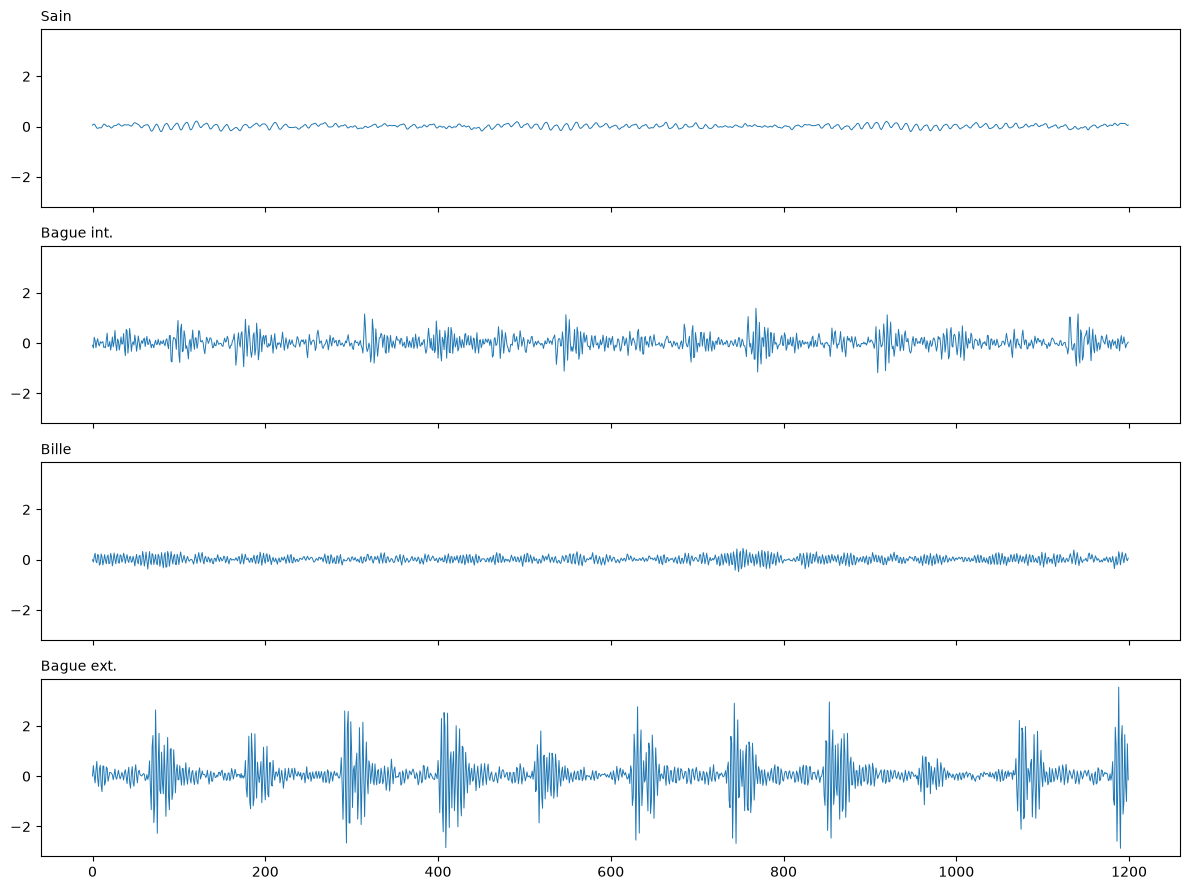

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True, sharey=True)
for ax, (nom, x) in zip(axes, signaux.items()):
    ax.plot(x[:1200], lw=0.7)
    ax.set_title(nom, loc="left", fontsize=10)
plt.tight_layout()
plt.show()
#sharey=True impose la même échelle verticale aux quatre graphiques. C’est indispensable pour comparer honnêtement les amplitudes.

In [3]:
#Tableau des indicateurs 
def indicateurs(x):
    rms = np.sqrt(np.mean(x**2))
    pic = np.max(np.abs(x))
    return {"RMS": rms, "Pic": pic, "Crête": pic / rms,
            "Kurtosis": kurtosis(x, fisher=False)}

tableau = pd.DataFrame({nom: indicateurs(x) for nom, x in signaux.items()}).T.round(2)
tableau

,RMS,Pic,Crête,Kurtosis
Sain,0.07,0.31,4.22,2.76
Bague int.,0.29,1.74,5.97,5.40
Bille,0.14,0.61,4.36,2.98
Bague ext.,0.67,3.63,5.42,7.65


- Sur les graphiques, les défauts Bague ext. et Bague int. sont ceux qui produisent les chocs les plus net. 
- Sur le tableau, les trois défauts de distinguent tous du sain avec les indicateurs : RMS, Pic et un peu moins sur Crête et Kurtosis pour le défaut Bille.  
- Le défaut Bille resemble au sain sur les indicateurs Crête et Kurtosis. 
- Pourquoi le défaut de bille ressemble au sain sur le facteur de crête et le kurtosis: 
Ces deux indicateurs mesurent le caractère impulsif du signal, c’est-à-dire la présence de chocs nets et rares. Or un défaut de bille produit des chocs faibles et irréguliers :

    - la bille tourne sur elle-même en roulant, donc le défaut ne touche pas les bagues à chaque passage. Selon son orientation, il frappe la bague intérieure, la bague extérieure, ou rien du tout ;
    - la bille se déplace aussi avec la cage. Elle n’est donc dans la zone de charge qu’une partie du temps, et les chocs sont souvent amortis.

Le résultat est un signal plus énergétique (le RMS augmente), mais pas vraiment impulsif : le kurtosis reste proche de 3. Les défauts de bague, eux, frappent régulièrement au même endroit, d’où leurs chocs francs. C’est bien connu dans la littérature : les défauts de bille du CWRU sont les plus difficiles à diagnostiquer.
- Aucun indicateur ne suffit seul. Le kurtosis rate la bille. Le RMS la détecte ici, mais il dépend de la charge, de la vitesse et du capteur, donc il est fragile pour comparer des machines entre elles.
- Il faudra combiner plusieurs indicateurs, puis ajouter l’analyse fréquentielle, qui repère les fréquences propres à chaque type de défaut.
- Une limite pour l’instant, nous avons une seule valeur par fichier. On ne connaît donc pas la variabilité à l’intérieur d’un enregistrement, et on ne peut pas dire si les différences observées sont nettes ou fragiles.